## 실습 설명
익중이는 배달 전문 음식점을 운영하고 있습니다. 다행히 맛집으로 소문이 났는지, 저녁 시간대에 들어오는 주문이 엄청 많아져서 새로운 배달 업체와 계약을 했다고 하네요. 일주일 정도 서비스를 이용해 본 뒤, 배달이 빠르게 잘 되고 있는지 배달 수수료로 얼마를 내고 있는지 등을 전반적으로 확인해 보려고 하는데요.  


일단 이 업체를 이용하기 시작한 날인 2022년 10월 17일의 데이터만 뽑아서 확인해 봅시다. 주문 시각(order_time)을 기준으로 데이터를 추출해 보세요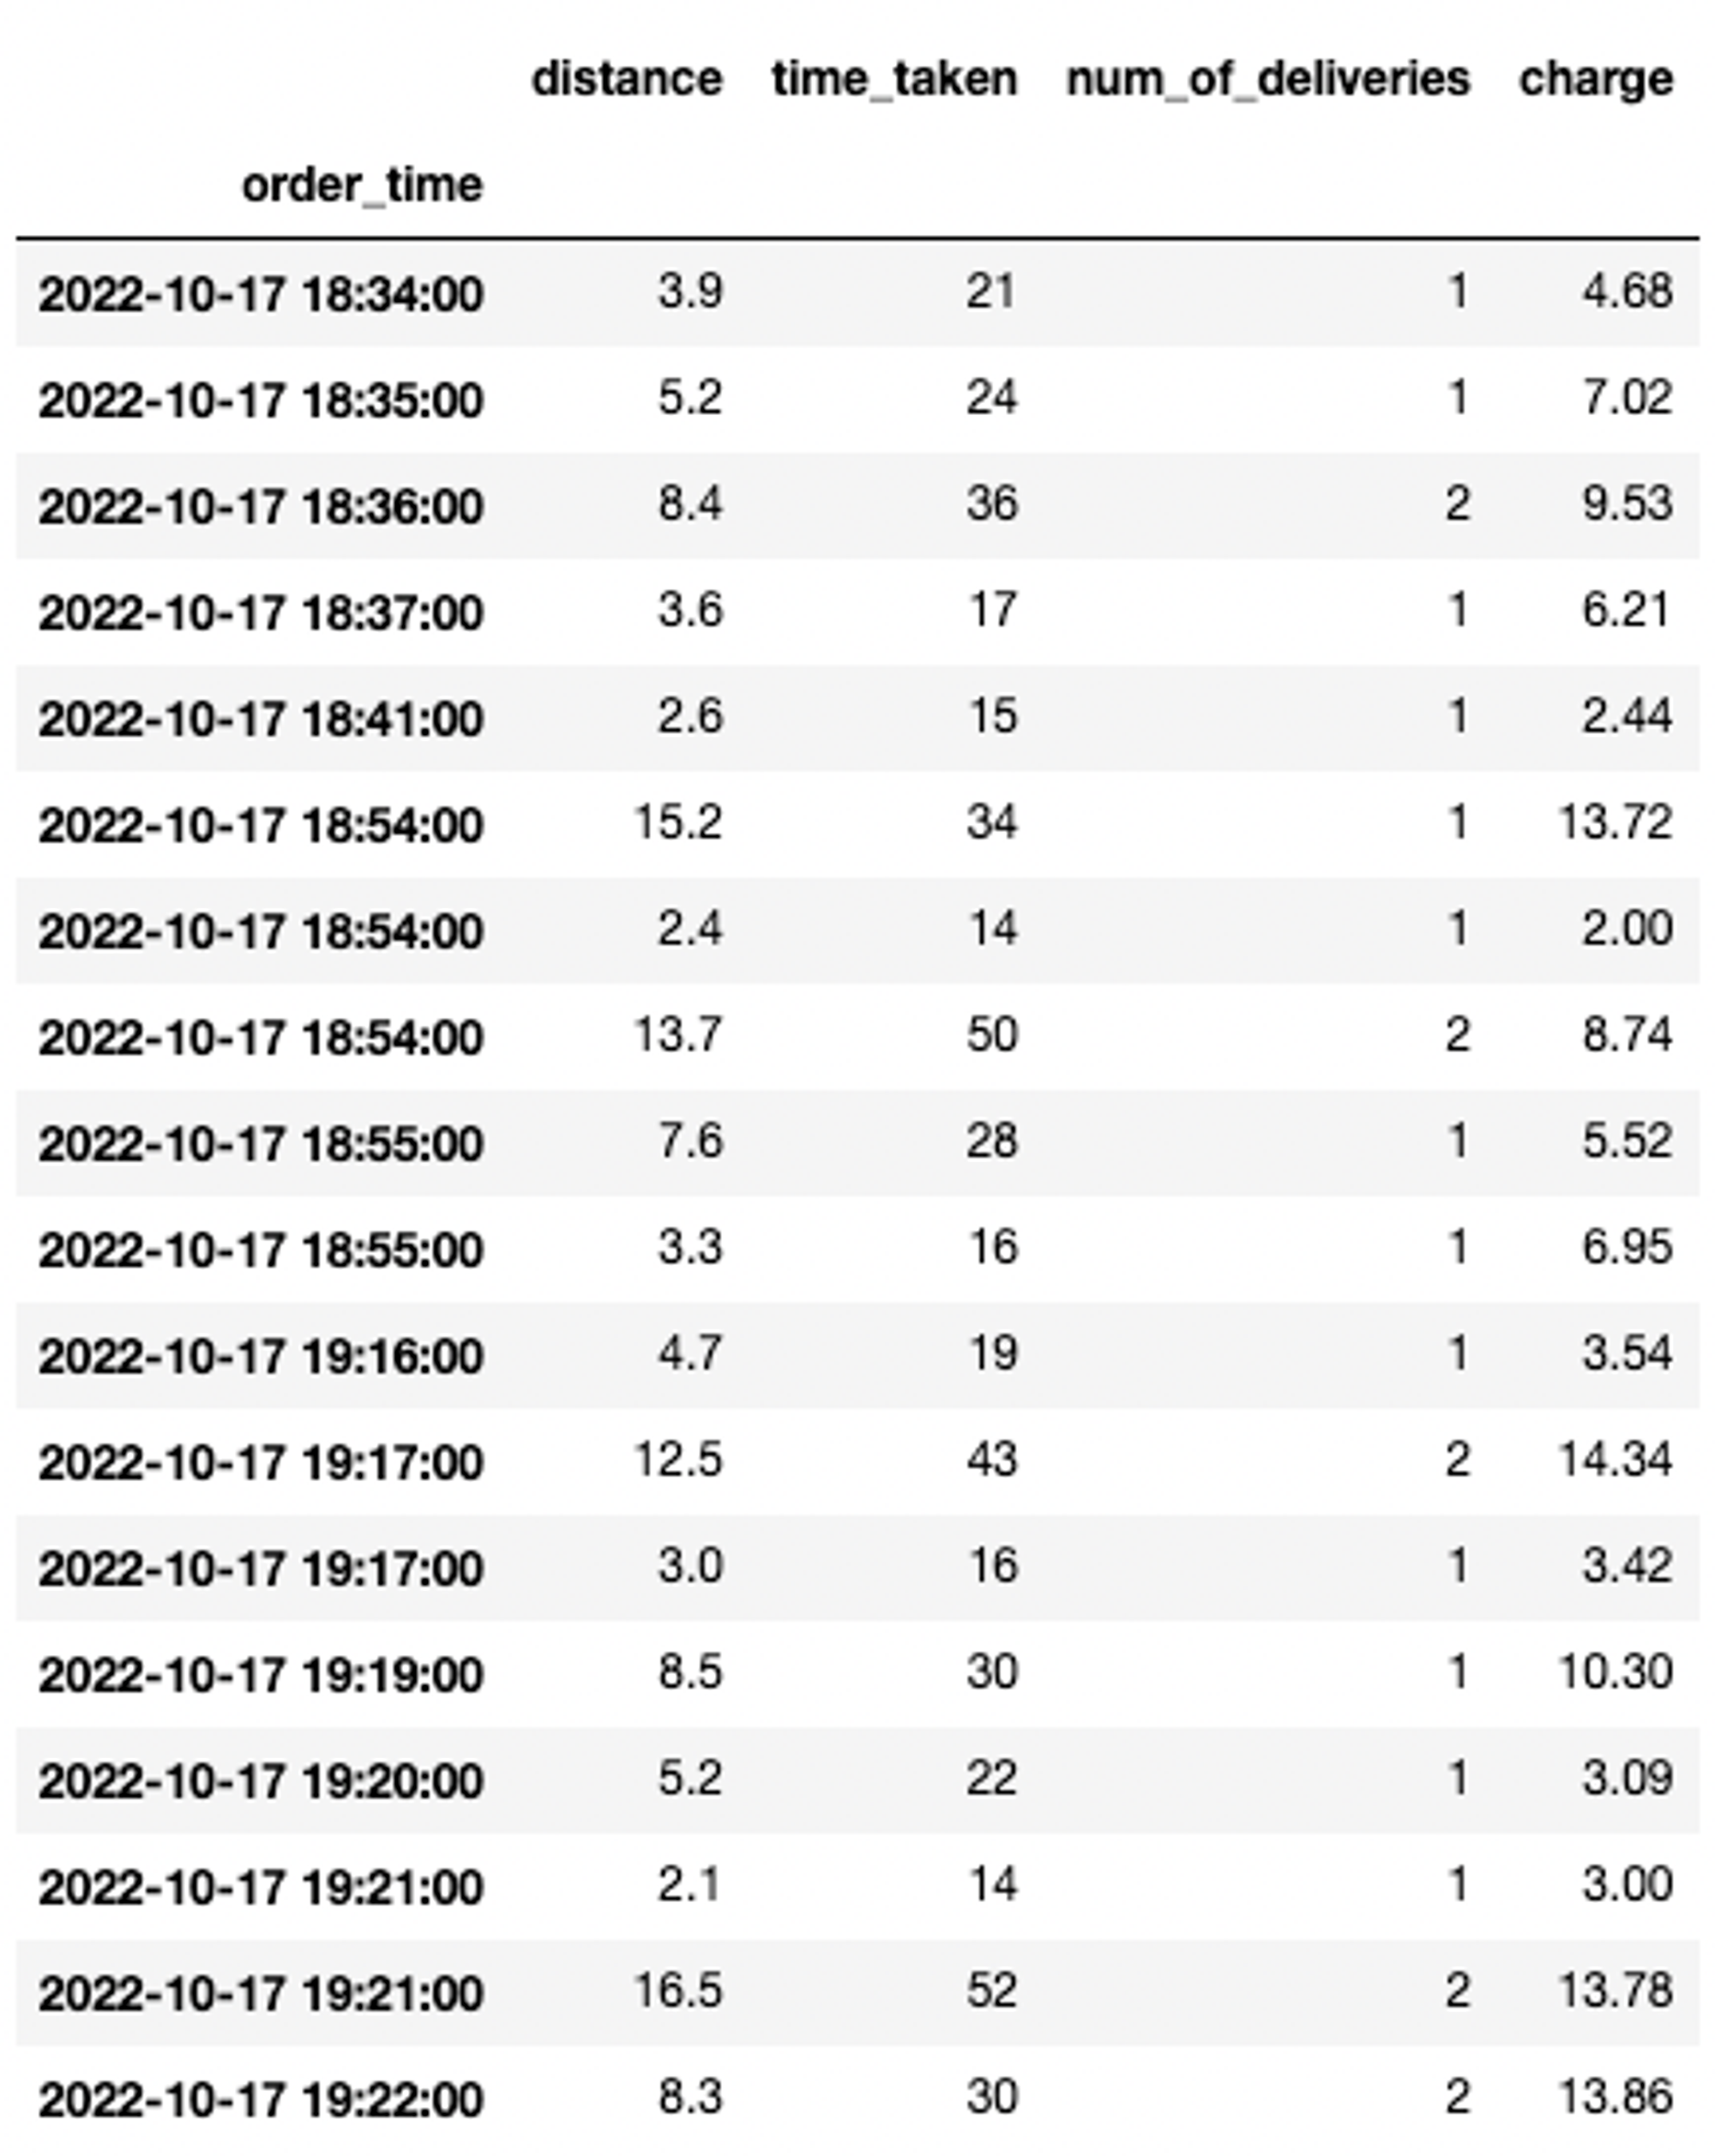



In [30]:
import pandas as pd

delivery_df = pd.read_csv('../data/delivery.csv')
delivery_df


,order_time,distance,time_taken,num_of_deliveries,charge
0,2022-10-17 18:34:00,3.9,21,1,4.68
1,2022-10-17 18:35:00,5.2,24,1,7.02
2,2022-10-17 18:36:00,8.4,36,2,9.53
3,2022-10-17 18:37:00,3.6,17,1,6.21
4,2022-10-17 18:41:00,2.6,15,1,2.44
...,...,...,...,...,...
104,2022-10-23 19:28:00,6.4,37,1,5.01
105,2022-10-23 19:28:00,3.9,26,2,7.34
106,2022-10-23 19:48:00,3.3,21,1,3.83
107,2022-10-23 19:49:00,5.8,22,1,5.80


In [31]:
delivery_df['order_time'] = pd.to_datetime(delivery_df['order_time'])

In [32]:
delivery_df.dtypes

order_time           datetime64[us]
distance                    float64
time_taken                    int64
num_of_deliveries             int64
charge                      float64
dtype: object

In [33]:
delivery_df = delivery_df.set_index('order_time').sort_index()

In [34]:
delivery_df.loc['2022-10-17']

,distance,time_taken,num_of_deliveries,charge
order_time,,,,
2022-10-17 18:34:00,3.9,21,1,4.68
2022-10-17 18:35:00,5.2,24,1,7.02
2022-10-17 18:36:00,8.4,36,2,9.53
2022-10-17 18:37:00,3.6,17,1,6.21
2022-10-17 18:41:00,2.6,15,1,2.44
2022-10-17 18:54:00,15.2,34,1,13.72
2022-10-17 18:54:00,2.4,14,1,2.00
2022-10-17 18:54:00,13.7,50,2,8.74
2022-10-17 18:55:00,7.6,28,1,5.52


## 실습 설명  
이번에는 배달 음식이 고객에게 도착한 시각을 계산해 봅시다. 주문 시각(order_time)과 배달 소요 시간(time_taken)을 가지고 배달 완료 시간을 계산해서 DataFrame에 delivery_time이라는 컬럼을 추가해 주세요! 참고로 time_taken 컬럼은 배달에 몇 분이 소요되었는지를 의미하므로, 아래 출력 결과처럼 분을 기준으로 한 Timedelta로 바꿔 주세요. 참고로 분을 의미하는 코드는 T 입니다.

주의 사항: 채점을 위해 가장 마지막 줄에는 delivery_df라고 입력해서 DataFrame을 출력해 주세요.

In [35]:
import pandas as pd

delivery_df = pd.read_csv('../data/delivery.csv', parse_dates=['order_time'])

In [36]:
delivery_df

,order_time,distance,time_taken,num_of_deliveries,charge
0,2022-10-17 18:34:00,3.9,21,1,4.68
1,2022-10-17 18:35:00,5.2,24,1,7.02
2,2022-10-17 18:36:00,8.4,36,2,9.53
3,2022-10-17 18:37:00,3.6,17,1,6.21
4,2022-10-17 18:41:00,2.6,15,1,2.44
...,...,...,...,...,...
104,2022-10-23 19:28:00,6.4,37,1,5.01
105,2022-10-23 19:28:00,3.9,26,2,7.34
106,2022-10-23 19:48:00,3.3,21,1,3.83
107,2022-10-23 19:49:00,5.8,22,1,5.80


In [37]:
delivery_df.dtypes

order_time           datetime64[us]
distance                    float64
time_taken                    int64
num_of_deliveries             int64
charge                      float64
dtype: object

In [50]:
delivery_df['time_taken'] = pd.to_timedelta(delivery_df['time_taken'],unit='min')

In [51]:
delivery_df

,order_time,distance,time_taken,num_of_deliveries,charge
0,2022-10-17 18:34:00,3.9,0 days 00:21:00,1,4.68
1,2022-10-17 18:35:00,5.2,0 days 00:24:00,1,7.02
2,2022-10-17 18:36:00,8.4,0 days 00:36:00,2,9.53
3,2022-10-17 18:37:00,3.6,0 days 00:17:00,1,6.21
4,2022-10-17 18:41:00,2.6,0 days 00:15:00,1,2.44
...,...,...,...,...,...
104,2022-10-23 19:28:00,6.4,0 days 00:37:00,1,5.01
105,2022-10-23 19:28:00,3.9,0 days 00:26:00,2,7.34
106,2022-10-23 19:48:00,3.3,0 days 00:21:00,1,3.83
107,2022-10-23 19:49:00,5.8,0 days 00:22:00,1,5.80


In [53]:
delivery_df['delivery_time'] = delivery_df['order_time'] + delivery_df['time_taken']
delivery_df

,order_time,distance,time_taken,num_of_deliveries,charge,delivery_time
0,2022-10-17 18:34:00,3.9,0 days 00:21:00,1,4.68,2022-10-17 18:55:00
1,2022-10-17 18:35:00,5.2,0 days 00:24:00,1,7.02,2022-10-17 18:59:00
2,2022-10-17 18:36:00,8.4,0 days 00:36:00,2,9.53,2022-10-17 19:12:00
3,2022-10-17 18:37:00,3.6,0 days 00:17:00,1,6.21,2022-10-17 18:54:00
4,2022-10-17 18:41:00,2.6,0 days 00:15:00,1,2.44,2022-10-17 18:56:00
...,...,...,...,...,...,...
104,2022-10-23 19:28:00,6.4,0 days 00:37:00,1,5.01,2022-10-23 20:05:00
105,2022-10-23 19:28:00,3.9,0 days 00:26:00,2,7.34,2022-10-23 19:54:00
106,2022-10-23 19:48:00,3.3,0 days 00:21:00,1,3.83,2022-10-23 20:09:00
107,2022-10-23 19:49:00,5.8,0 days 00:22:00,1,5.80,2022-10-23 20:11:00
